# E1. Propuesta, teardown e intervención preliminar

**EfficientNet-B0 (ImageNet) para detección de deepfakes en DFDC, parte 0**

Curso INF659 · Deep Learning · Maestría · semestre 2026-2 <br/>
Entregable E1 · 12 de octubre de 2026 <br/>
Integrantes:
- Christian Carhuancho
- Jorge Fatama
- Jorge Chamorro
</br>

Este cuaderno cubre las cuatro piezas pedidas para E1:

1. Propuesta y pregunta de investigación.
2. Related work inicial.
3. Teardown instrumentado del núcleo (Fase A).
4. Intervención preliminar con hipótesis escrita antes de medir (inicio de la Fase B).
5. Cuaderno de decisiones, con el uso de asistencia de IA.


## 1. Propuesta

**Pregunta.** Dentro de EfficientNet-B0, la recalibración de canales del bloque Squeeze-and-Excitation, ¿aporta señal para separar un vídeo real de un deepfake en DFDC, o la decisión queda en las convoluciones espaciales del residual invertido?

**Por qué esta pregunta.** EfficientNet no es una bolsa de capas iguales. Cada bloque MBConv tiene una pieza distinta del resto: una puerta que mira el mapa entero, lo comprime a un vector y reescala los canales. Esa puerta es el núcleo que se puede apagar sin redibujar la red y sin tirar los pesos ImageNet de las convoluciones. Si al apagarla el detector no cambia, SE no era carga de la decisión en este dato. Si baja el AUC, la puerta sí estaba usando canales que, en la literatura, suelen ser frágiles cuando cambia el método de falsificación.

**Contribución que este E1 deja abierta.** Una estrategia de generalización entre métodos de falsificación apoyada en ese diagnóstico. E1 no la valida: solo abre el bloque, mide el efecto en una sola partición (`dfdc_train_part_0`) y deja registrada la hipótesis.

**Protocolo base, fijado antes de entrenar.**

| Pieza | Elección |
| --- | --- |
| Arquitectura | EfficientNet-B0 |
| Pesos iniciales | ImageNet-1K (tarjeta de torchvision, acc@1 publicada 77.692) |
| Régimen | Fine-tuning completo: todos los parámetros reciben gradiente, cinco épocas |
| Entrada | Recorte cuadrado de la cara, 224×224 |
| Salida | Probabilidad de FAKE por frame; el vídeo se resume con la media |
| Métrica de la hipótesis | AUC de vídeo en la época 5 |
| Semilla | 42 |

**Dato de esta corrida.** Solo la carpeta `Deepfake_Data/dfdc_train_part_00/dfdc_train_part_0`. El inventario de abajo cuenta las etiquetas. El metadato de DFDC guarda, para cada FAKE, el nombre del vídeo original: esa columna decide la partición, porque partir clip a clip metería la misma cara en entrenamiento y validación.


## 2. Related work inicial

La detección de deepfakes se evaluó en grande con el Deepfake Detection Challenge. Dolhansky et al. (2020) publican DFDC: decenas de miles de vídeos de personas que consintieron, con falsificaciones de varios métodos y una compresión parecida a la de una red social. El punto del reto no era el accuracy dentro de un generador visto en entrenamiento, sino sostener el detector cuando el método de falsificación cambia. Esa sigue siendo la pregunta del banco de proyectos del curso.

La familia de modelos que quedó como referencia de ingeniería del reto es EfficientNet (Tan y Le, 2019). La red base, B0, sale de una búsqueda de arquitectura bajo un presupuesto de cómputo de unos 0.39 mil millones de multiply-adds y 5.3 millones de parámetros. El resto de la familia no se rediseña bloque a bloque: se escala con una regla compuesta. Con un coeficiente φ, la profundidad crece como α^φ, el ancho como β^φ y la resolución como γ^φ, con α = 1.2, β = 1.1, γ = 1.15 y α · β² · γ² ≈ 2. B0 es el caso φ = 0. Por eso sirve para abrir el núcleo: es la red pequeña de la que salen B4–B7, cabe en una GPU de 12 GB y tiene el mismo bloque que las variantes grandes.

Ese bloque es el MBConv. Hereda el residual invertido de MobileNetV2 (Sandler et al., 2018): una convolución 1×1 expande canales, una depthwise de k×k mezcla el espacio de cada canal, y otra 1×1 proyecta de vuelta. Si el salto espacial es 1 y los canales de entrada y salida coinciden, hay un atajo aditivo. Encima, EfficientNet inserta Squeeze-and-Excitation (Hu, Shen y Sun, 2018): un pooling global, un cuello de botella (en esta implementación, un cuarto de los canales de entrada del bloque) y una sigmoide que multiplica a cada canal. La activación del bloque es SiLU. Además, la red usa stochastic depth (Huang et al., 2016), con probabilidad que crece con la profundidad hasta 0.2, y un dropout de 0.2 antes del clasificador. Nada de esto es un detalle de la API: es la forma del modelo, y el teardown de abajo lo cuenta sobre el objeto de torchvision, no sobre el diagrama del paper.

En DFDC, la solución pública del primer puesto (Seferbekov, 2020; repositorio, no artículo) entrena ensambles de EfficientNet grandes sobre caras recortadas. Bonettini et al. (ICPR 2020) hacen un ensamble de EfficientNet-B4 para manipulación facial en vídeo. Esa línea trata a la red como un extractor que se fine-tunea. En paralelo, otros trabajos mueven el núcleo hacia el artefacto: Face X-ray (Li et al., 2020) busca la frontera de mezcla; F3-Net (Qian et al., 2020) mina pistas de frecuencia; LipForensics (Haliassos et al., 2021) se apoya en la boca, con la idea de que el habla es más estable entre generadores; Zhao et al. (2021) usan varias atenciones. Shiohara y Yamasaki (2022) muestran que imágenes auto-mezcladas mejoran la generalización. Ojha, Li y Lee (2023) dan un paso más: un clasificador lineal sobre features de CLIP, sin ver los generadores de prueba, supera a detectores entrenados en un solo tipo de falsificación. El patrón es incómodo para un EfficientNet fine-tuneado en DFDC: mucho del rendimiento publicado no viaja a otro generador.

Hay un atajo más cercano al protocolo de este cuaderno. Dong et al. (2023) argumentan que los detectores filtran la identidad de la persona y que esa fuga impide medir generalización. En DFDC cada FAKE declara su vídeo original. Si un split aleatorio de clips deja la misma identidad a ambos lados, el AUC puede premiar “conozco esta cara” y no “veo un artefacto”. Por eso la partición de abajo es por identidad.

**Dónde se coloca este E1.** No propone otro detector ni compite con el ensamble de Seferbekov. Abre el MBConv de la familia que ese ensamble usó, aísla la puerta SE y mide, en una sola parte de DFDC y con una semilla, si esa puerta mueve el AUC de vídeo. El related work de la entrega final tiene que contrastar este diagnóstico con los métodos de artefacto y con los detectores de features congeladas. Aquí solo queda nombrada esa distancia.


## 3. Cuaderno de decisiones

Cada fila se escribió como decisión de protocolo, no como conclusión de un resultado. La columna de IA dice qué parte del texto o del código asistió un agente en Cursor (Grok 4.7). La elección del modelo y del régimen de cinco épocas es del equipo.

| ID | Decisión | Por qué | Qué no hacemos en E1 | IA |
| --- | --- | --- | --- | --- |
| D1 | EfficientNet-B0, pesos ImageNet-1K, fine-tuning completo, 5 épocas | B0 es el φ = 0 de la familia que dominó DFDC. Cinco épocas es el protocolo acordado. Fine-tuning completo significa que el núcleo MBConv sí recibe gradiente; congelar el backbone no permitiría ver si el núcleo se adapta | No usamos B4/B7, ni linear probing, ni un learning rate distinto para la cabeza y el tronco | El equipo eligió el modelo y las cinco épocas. La IA implementó el protocolo |
| D2 | La entrada es un recorte cuadrado de cara (YuNet, margen 1.3, 224 px), no el frame entero | En DFDC la manipulación está en la cara. El fondo y la compresión del frame son un atajo fácil | No estimamos pose ni landmarks como features | La IA propuso YuNet y el margen. Hay que poder defender por qué no entra el frame completo |
| D3 | La partición es por identidad (el campo `original` del FAKE, o el propio nombre si es REAL), 80/20, semilla 42 | Dong et al. (2023): si la misma persona cae en los dos lados, el modelo puede memorizar identidad. En esta carpeta el código comprueba además que todo FAKE apunta a un REAL local | No hay split por clip. No hay segunda partición de DFDC en este E1 | La IA señaló el riesgo y escribió el split. La defensa tiene que explicar el campo `original` |
| D4 | Entran todos los vídeos de `dfdc_train_part_0`. Pérdida: entropía cruzada con peso inverso a la frecuencia de frames de entrenamiento. Métrica de la hipótesis: AUC de vídeo | La carpeta está muy desbalanceada. La accuracy de un clasificador que siempre dice FAKE es justo la fracción de FAKE. El AUC no depende de ese prior ni de un umbral | No submuestreamos FAKE para “balancear el accuracy”. No calibramos el umbral 0.5 | La IA propuso el peso de clase y el AUC como métrica principal |
| D5 | La intervención es sustituir cada SqueezeExcitation por `Identity`. Las convoluciones, el residual y los pesos ImageNet de esas convoluciones se quedan | SE es la única atención de canal del bloque. Apagarla aísla una pieza. Cambiar SiLU por ReLU, o el residual por concatenación, son otras intervenciones y se mezclarían con esta | No se poda, no se cuantiza, no se cambia la pérdida | La IA propuso esta ablación como primera intervención de núcleo. La hipótesis H1 es la que hay que defender |
| D6 | Una sola tasa, AdamW a 1e-4, weight decay 1e-4, coseno en 5 épocas. La hipótesis se lee en la época 5, no en la mejor época de validación | Elegir la mejor época con el mismo val que se reporta infla el resultado. El coseno y la tasa quedan fijos para no sumar una búsqueda | No hay early stopping. No hay learning rate discriminativo. La mejor época se informa aparte y no decide H1 | La IA escribió el bucle. La tasa no se reajustó después de ver la curva: si el entrenamiento es inestable, eso se reporta |
| D7 | Una semilla de entrenamiento (42). Incertidumbre: bootstrap pareado de los vídeos de validación, 1000 remuestras, percentiles 5 y 95 | Repetir cinco semillas es el estándar del curso y no cabe como preliminares de hoy. El bootstrap describe la variación del AUC en esta partición; no describe otra semilla ni otra partición | No se declara significancia fuera de esta partición | La IA escribió el bootstrap. La regla de lectura de abajo está fijada antes de entrenar |
| D8 | 8 frames uniformes por vídeo. Aumento: solo volteo horizontal. Normalización ImageNet. Si YuNet no ve cara, recorte central y se cuenta la tasa | Ocho frames cubren el clip sin convertir el E1 en un modelo temporal. Más aumentos confundirían el efecto de SE con el de la aumentación | No hay modelo de secuencia ni fusión aprendida. La media de frames es la agregación | La IA implementó el muestreo |

**Asistencia de IA, en una frase.** El agente estructuró el cuaderno, la instrumentación del teardown y el código de la ablación.

**Regla de lectura, registrada antes de la corrida.** Sea Δ = AUC(sin SE) − AUC(con SE) en la época 5, a nivel de vídeo. H1 dice que Δ es negativo. Se considera compatible con H1 solo si el percentil 95 del bootstrap pareado es menor que 0. Se considera contraria a H1 si el percentil 5 es mayor que 0. Si el intervalo contiene 0, esta preliminar no distingue las dos variantes.

**Hipótesis secundaria, también previa.** H2: con decenas de identidades y fine-tuning completo, la pérdida de entrenamiento baja más deprisa de lo que se sostiene el AUC de validación. H2 no habla de SE. Evita leer un modelo memorizado como si fuera un efecto del núcleo.

### 3.1 Datos, sesgo y ética

DFDC muestra a personas reales. El uso de esta carpeta se limita al curso y a los términos con los que Meta publicó el conjunto; los vídeos y los recortes de cara no se redistribuyen. El metadato de la parte 0 trae etiqueta, split e identidad de origen, y no trae edad, sexo ni tono de piel: este E1 no puede afirmar equidad demográfica, y un detector que falle de forma distinta por grupo sería un daño concreto (acusar un vídeo real, o dejar pasar una falsificación). La métrica principal es el AUC precisamente porque un umbral mal puesto convierte ese daño en una decisión.


## 4. Entorno y datos

El cuaderno se ejecuta desde la raíz del proyecto, con GPU si está disponible. OpenCV 5 no abre el ONNX de YuNet que publica el zoo de OpenCV, así que hace falta `opencv-python-headless` 4.x. En Windows, el importador ONNX de OpenCV no lee rutas con la letra `í`; el archivo se copia a una ruta ASCII temporal y el peso vive en `modelos/`.


In [ ]:
%matplotlib inline

import csv
import json
import random
import shutil
import sys
import time
import urllib.request
import warnings
from collections import defaultdict
from pathlib import Path

import av
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import balanced_accuracy_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torch.utils.flop_counter import FlopCounterMode
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from torchvision.ops import SqueezeExcitation, StochasticDepth
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="triton not found")

SEED = 42
EPOCHS = 5
FRAMES_PER_VIDEO = 8
BATCH_SIZE = 32
LR = 1e-4
WEIGHT_DECAY = 1e-4
FACE_SCALE = 1.3
BOOTSTRAP_DRAWS = 1000
YUNET_URL = (
    "https://github.com/opencv/opencv_zoo/raw/main/models/"
    "face_detection_yunet/face_detection_yunet_2023mar.onnx"
)


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "Deepfake_Data").is_dir():
            return candidate
    raise FileNotFoundError(
        "No aparece Deepfake_Data. Abre el cuaderno en la raíz del proyecto."
    )


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


ROOT = find_root()
DATA_DIR = ROOT / "Deepfake_Data" / "dfdc_train_part_00" / "dfdc_train_part_0"
META_PATH = DATA_DIR / "metadata.json"
FIG_DIR = ROOT / "e1_figuras"
OUT_DIR = ROOT / "resultados" / "e1"
CACHE_DIR = ROOT / "cache" / "e1_part0_faces"
YUNET_LOCAL = ROOT / "modelos" / "face_detection_yunet_2023mar.onnx"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "font.size": 11, "figure.dpi": 120})

versions = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cv2": cv2.__version__,
    "numpy": np.__version__,
    "av": av.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
}
print(json.dumps(versions, indent=2))
if int(cv2.__version__.split(".")[0]) >= 5:
    raise RuntimeError("Hace falta opencv-python-headless 4.x para leer el ONNX de YuNet.")
(OUT_DIR / "entorno.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")


W1012 03:49:48.545000 38252 torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


{
  "python": "3.12.6",
  "torch": "2.14.1+cu126",
  "cv2": "4.14.0",
  "numpy": "2.2.3",
  "av": "19.0.1",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3060"
}


C:\Users\Jorge Fatama Vera\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


164

vídeos con metadato y archivo: 1334
REAL 86 | FAKE 1248 | fracción FAKE 0.936
archivos de metadato sin mp4: 0
mp4 sin metadato: 0
FAKE cuyo original no es un REAL de esta carpeta: 0
FAKE por identidad REAL: min 1 | mediana 11 | max 36
Accuracy de un clasificador que siempre responde FAKE: 0.936. Esa cifra no mide detección.


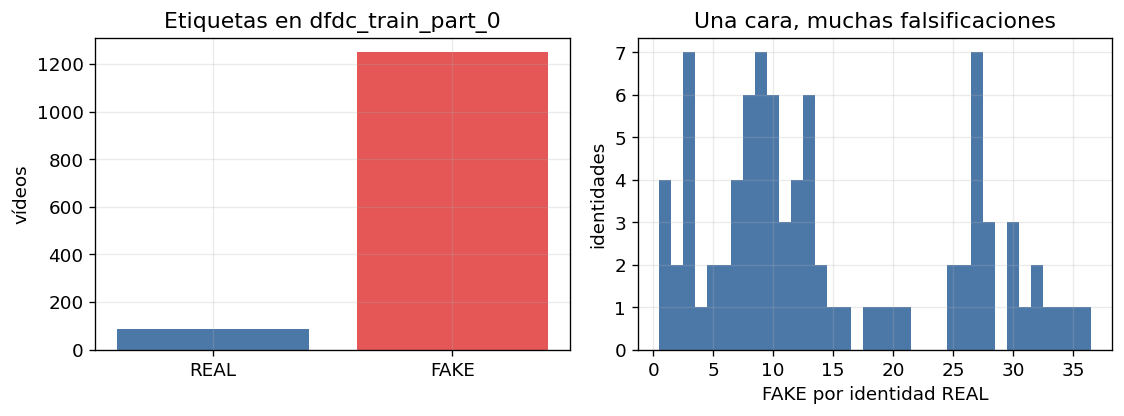

In [ ]:
metadata = json.loads(META_PATH.read_text(encoding="utf-8"))
on_disk = {path.name for path in DATA_DIR.glob("*.mp4")}
names = sorted(set(metadata) & on_disk)
missing_files = sorted(set(metadata) - on_disk)
unknown_files = sorted(on_disk - set(metadata))

labels = {name: metadata[name]["label"] for name in names}
n_real = sum(label == "REAL" for label in labels.values())
n_fake = sum(label == "FAKE" for label in labels.values())


def identity_of(name: str) -> str:
    info = metadata[name]
    if info["label"] == "REAL":
        return name
    return info.get("original") or name


fakes_per_identity = defaultdict(int)
original_outside = 0
for name in names:
    if labels[name] != "FAKE":
        continue
    original = metadata[name].get("original")
    if original not in labels or labels.get(original) != "REAL":
        original_outside += 1
    fakes_per_identity[identity_of(name)] += 1

counts = np.array([fakes_per_identity[name] for name in names if labels[name] == "REAL"])

print(f"vídeos con metadato y archivo: {len(names)}")
print(f"REAL {n_real} | FAKE {n_fake} | fracción FAKE {n_fake / len(names):.3f}")
print(f"archivos de metadato sin mp4: {len(missing_files)}")
print(f"mp4 sin metadato: {len(unknown_files)}")
print(f"FAKE cuyo original no es un REAL de esta carpeta: {original_outside}")
print(
    "FAKE por identidad REAL: "
    f"min {counts.min()} | mediana {np.median(counts):.0f} | max {counts.max()}"
)
print(
    "Accuracy de un clasificador que siempre responde FAKE: "
    f"{n_fake / len(names):.3f}. Esa cifra no mide detección."
)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].bar(["REAL", "FAKE"], [n_real, n_fake], color=["#4C78A8", "#E45756"])
axes[0].set_ylabel("vídeos")
axes[0].set_title("Etiquetas en dfdc_train_part_0")
axes[1].hist(counts, bins=range(1, int(counts.max()) + 2), color="#4C78A8", align="left")
axes[1].set_xlabel("FAKE por identidad REAL")
axes[1].set_ylabel("identidades")
axes[1].set_title("Una cara, muchas falsificaciones")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_inventario_part0.png", bbox_inches="tight")
plt.show()


## 5. Teardown del núcleo

EfficientNet-B0, en el código de torchvision, es una secuencia `features` de nueve etapas, un pooling global y un clasificador (dropout y lineal). La etapa 0 es el stem (conv 3×3, stride 2, 32 canales, SiLU). Las siete siguientes son grupos de MBConv. La última es una conv 1×1 hacia 1280 canales. La cabeza ImageNet de 1000 clases se sustituye por una lineal a 2: REAL = 0, FAKE = 1. Esa sustitución es transferencia estándar, no la intervención del núcleo. La intervención es la sección 6.

Un MBConv hace, en este orden: expansión 1×1 (si el factor de expansión no es 1), depthwise k×k, Squeeze-and-Excitation, proyección 1×1 sin activación, y, si el stride es 1 y los canales coinciden, suma residual después de stochastic depth. El primer grupo no expande (factor 1): la depthwise opera sobre los 32 canales del stem y proyecta a 16.

**Qué se mide, y con qué fórmula.**

- Parámetros: elementos entrenables de cada etapa, incluidos BatchNorm y las dos conv 1×1 de SE.
- Multiply-adds. `FlopCounterMode` de PyTorch cuenta una multiplicación y una suma como dos FLOPs. El paper y la ficha de torchvision reportan multiply-adds (unos 0.39 mil millones). Por eso se publica MAC = FLOPs del contador / 2. Para una convolución, MAC = K_h · K_w · (C_in / groups) · C_out · H_out · W_out.
- Campo receptivo del camino convolucional. Se parte de r = 1, salto j = 1. Cada conv actualiza r ← r + ((k − 1)·d + 1 − 1) · j y j ← j · s. Un kernel 1×1 no cambia r ni j. Este número no ve el pooling global de SE: la puerta de canal, en cada posición, depende del mapa entero. El campo del logit, después del average pool, es r + (H − 1) · j sobre el último mapa.
- Latencia y memoria pico en la GPU de esta máquina, en evaluación, con entradas aleatorias 224×224. Es costo de la arquitectura, no tiempo de entrenamiento.

El stem ilustra la recurrencia: una conv 3×3 con stride 2 lleva r de 1 a 3 y el salto de 1 a 2. A la salida de esa capa, cada celda mira 3 píxeles de la imagen y las celdas están separadas por 2 píxeles.


normalización ImageNet (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
ficha torchvision {'num_params': 5288548, '_ops': 0.386, '_docs': 'These weights are ported from the original paper.'}
ImageNet-1K {'acc@1': 77.692, 'acc@5': 93.532}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Jorge Fatama Vera/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


  0%|          | 0.00/20.5M [00:00<?, ?B/s]

  6%|▌         | 1.25M/20.5M [00:00<00:01, 12.0MB/s]

 12%|█▏        | 2.50M/20.5M [00:00<00:01, 11.9MB/s]

 18%|█▊        | 3.75M/20.5M [00:00<00:01, 11.8MB/s]

...

 86%|████████▌ | 17.5M/20.5M [00:01<00:00, 11.8MB/s]

 92%|█████████▏| 18.8M/20.5M [00:01<00:00, 11.8MB/s]

 98%|█████████▊| 20.0M/20.5M [00:01<00:00, 11.8MB/s]

100%|██████████| 20.5M/20.5M [00:01<00:00, 11.8MB/s]

logits (1, 2) | RF del camino conv en el último mapa: 851 px | salto 32
RF efectivo del logit tras el average pool: 1043 px (el recorte mide 224)
parámetros del modelo con cabeza de 2 clases: 4,010,110 | suma de etapas 4,010,110
La ficha de torchvision (5,288,548) cuenta la cabeza ImageNet de 1000 clases. La diferencia es esa capa lineal, no un cambio en el tronco.
MACs de una imagen 224 (cabeza de 2 clases): 0.3845 mil millones
etapa                  salida                 params         MACs     RF   SE
-----------------------------------------------------------------------------
0 stem conv3 s2        32x112x112                928   10,838,016      3    0
1 MBConv1 k3 ×1        16x112x112              1,448   10,035,712      7    1
2 MBConv6 k3 s2 ×2     24x56x56               16,714   54,945,216     19    2
3 MBConv6 k5 s2 ×2     40x28x28               46,640   37,939,584     67    2
4 MBConv6 k3 s2 ×3     80x14x14              242,930   43,555,200    147    3
5 MBConv6 k5 ×3      

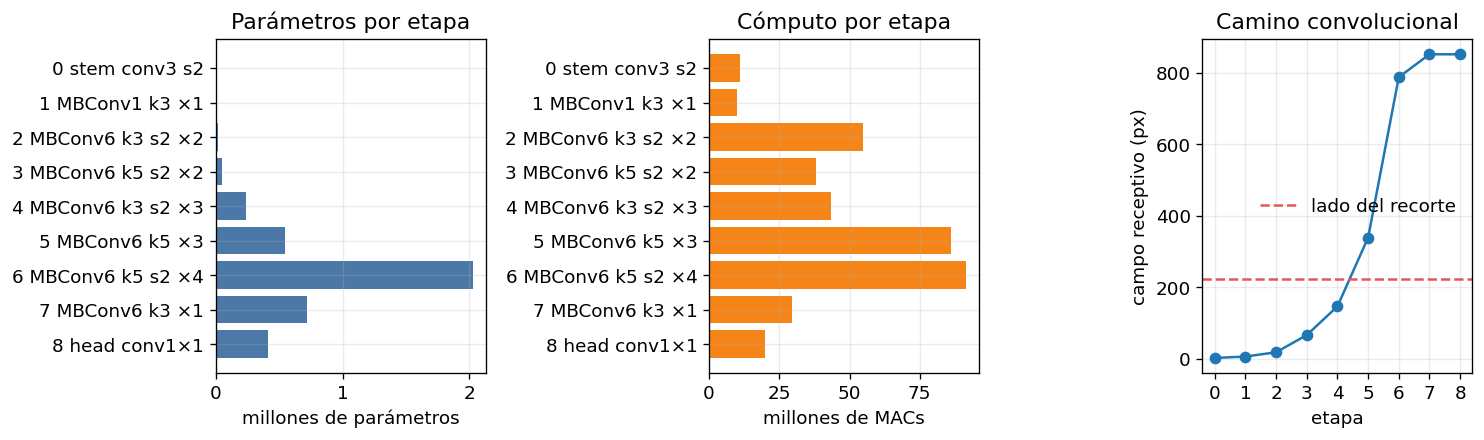

2175

In [ ]:
IMAGENET_WEIGHTS = EfficientNet_B0_Weights.IMAGENET1K_V1
PREPROCESS = IMAGENET_WEIGHTS.transforms()
IMAGENET_MEAN = tuple(PREPROCESS.mean)
IMAGENET_STD = tuple(PREPROCESS.std)
print("normalización ImageNet", IMAGENET_MEAN, IMAGENET_STD)
print("ficha torchvision", {k: IMAGENET_WEIGHTS.meta[k] for k in ("num_params", "_ops", "_docs")})
print("ImageNet-1K", IMAGENET_WEIGHTS.meta["_metrics"]["ImageNet-1K"])


def build_b0(num_classes: int = 2) -> nn.Module:
    model = efficientnet_b0(weights=IMAGENET_WEIGHTS)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def advance_receptive_field(rf: int, jump: int, conv: nn.Conv2d) -> tuple[int, int]:
    kernel = conv.kernel_size[0]
    stride = conv.stride[0]
    dilation = conv.dilation[0]
    kernel_eff = (kernel - 1) * dilation + 1
    rf = rf + (kernel_eff - 1) * jump
    jump = jump * stride
    return rf, jump


def receptive_field_of(module: nn.Module, rf: int, jump: int) -> tuple[int, int]:
    for layer in module.modules():
        if isinstance(layer, nn.Conv2d):
            rf, jump = advance_receptive_field(rf, jump, layer)
    return rf, jump


def macs_of(module: nn.Module, tensor: torch.Tensor) -> tuple[int, torch.Tensor]:
    counter = FlopCounterMode(display=False)
    with counter:
        output = module(tensor)
    return counter.get_total_flops() // 2, output


set_seed(SEED)
model = build_b0(2).eval()

STAGE_NAMES = [
    "0 stem conv3 s2",
    "1 MBConv1 k3 ×1",
    "2 MBConv6 k3 s2 ×2",
    "3 MBConv6 k5 s2 ×2",
    "4 MBConv6 k3 s2 ×3",
    "5 MBConv6 k5 ×3",
    "6 MBConv6 k5 s2 ×4",
    "7 MBConv6 k3 ×1",
    "8 head conv1×1",
]

rows = []
rf, jump = 1, 1
probe = torch.zeros(1, 3, 224, 224)
total_macs = 0
with torch.no_grad():
    for index, stage in enumerate(model.features):
        params = sum(p.numel() for p in stage.parameters())
        se_blocks = sum(isinstance(m, SqueezeExcitation) for m in stage.modules())
        macs, probe = macs_of(stage, probe)
        rf, jump = receptive_field_of(stage, rf, jump)
        total_macs += macs
        rows.append(
            {
                "etapa": STAGE_NAMES[index],
                "salida": tuple(probe.shape),
                "params": params,
                "macs": macs,
                "rf_conv": rf,
                "salto": jump,
                "se": se_blocks,
            }
        )

head = nn.Sequential(model.avgpool, nn.Flatten(1), model.classifier)
head_params = sum(p.numel() for p in model.classifier.parameters())
with torch.no_grad():
    head_macs, logits = macs_of(head, probe)
rf_logits = rf + (probe.shape[-2] - 1) * jump
total_macs += head_macs
total_params = sum(p.numel() for p in model.parameters())
accounted = sum(row["params"] for row in rows) + head_params

print(f"logits {tuple(logits.shape)} | RF del camino conv en el último mapa: {rf} px | salto {jump}")
print(f"RF efectivo del logit tras el average pool: {rf_logits} px (el recorte mide 224)")
print(f"parámetros del modelo con cabeza de 2 clases: {total_params:,} | suma de etapas {accounted:,}")
print(
    "La ficha de torchvision (5,288,548) cuenta la cabeza ImageNet de 1000 clases. "
    "La diferencia es esa capa lineal, no un cambio en el tronco."
)
print(f"MACs de una imagen 224 (cabeza de 2 clases): {total_macs / 1e9:.4f} mil millones")
assert accounted == total_params

header = f"{'etapa':<22} {'salida':<18} {'params':>10} {'MACs':>12} {'RF':>6} {'SE':>4}"
print(header)
print("-" * len(header))
for row in rows:
    shape = "x".join(str(v) for v in row["salida"][1:])
    print(
        f"{row['etapa']:<22} {shape:<18} {row['params']:>10,} {row['macs']:>12,} "
        f"{row['rf_conv']:>6} {row['se']:>4}"
    )
print(f"{'pool + lineal 2':<22} {'2':<18} {head_params:>10,} {head_macs:>12,}")

residual_blocks = [m for m in model.modules() if getattr(m, "use_res_connect", False)]
depth_probs = [m.p for m in model.modules() if isinstance(m, StochasticDepth)]
se_params = sum(p.numel() for m in model.modules() if isinstance(m, SqueezeExcitation) for p in m.parameters())
print(f"MBConv con residual aditivo: {len(residual_blocks)}")
print(f"parámetros dentro de SE: {se_params:,} ({100 * se_params / total_params:.2f}% del total)")
print("stochastic depth por bloque:", ", ".join(f"{p:.3f}" for p in depth_probs))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
axes[0].barh([row["etapa"] for row in rows][::-1], [row["params"] / 1e6 for row in rows][::-1], color="#4C78A8")
axes[0].set_xlabel("millones de parámetros")
axes[0].set_title("Parámetros por etapa")
axes[1].barh([row["etapa"] for row in rows][::-1], [row["macs"] / 1e6 for row in rows][::-1], color="#F58518")
axes[1].set_xlabel("millones de MACs")
axes[1].set_title("Cómputo por etapa")
axes[2].plot([row["rf_conv"] for row in rows], marker="o")
axes[2].axhline(224, color="#E45756", ls="--", label="lado del recorte")
axes[2].set_xticks(range(len(rows)))
axes[2].set_xticklabels([str(i) for i in range(len(rows))])
axes[2].set_xlabel("etapa")
axes[2].set_ylabel("campo receptivo (px)")
axes[2].set_title("Camino convolucional")
axes[2].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_teardown_etapas.png", bbox_inches="tight")
plt.show()

(OUT_DIR / "teardown_etapas.json").write_text(
    json.dumps(
        {
            "params": total_params,
            "macs": total_macs,
            "rf_ultimo_mapa": rf,
            "rf_logit": rf_logits,
            "se_params": se_params,
            "etapas": rows,
        },
        indent=2,
    ),
    encoding="utf-8",
)


In [ ]:
def measure_latency(net: nn.Module, batch: int, steps: int = 50, warmup: int = 20) -> dict:
    net = net.to(DEVICE).eval()
    sample = torch.randn(batch, 3, 224, 224, device=DEVICE)
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        for _ in range(warmup):
            net(sample)
        torch.cuda.synchronize()
        start, end = torch.cuda.Event(True), torch.cuda.Event(True)
        start.record()
        for _ in range(steps):
            net(sample)
        end.record()
        torch.cuda.synchronize()
    milliseconds = start.elapsed_time(end) / steps
    peak = torch.cuda.max_memory_allocated()
    return {
        "batch": batch,
        "ms_por_paso": round(milliseconds, 3),
        "imagenes_por_s": round(1000 * batch / milliseconds, 1),
        "memoria_pico_MB": round(peak / (1024 ** 2), 1),
    }


if DEVICE.type != "cuda":
    print("Sin CUDA: no se mide latencia de GPU.")
    latency_rows = []
else:
    latency_rows = [measure_latency(model, batch) for batch in (1, 16)]
    for row in latency_rows:
        print(row)

param_mb = sum(p.numel() for p in model.parameters()) * 4 / (1024 ** 2)
print(f"pesos en fp32: {param_mb:.2f} MB")


{'batch': 1, 'ms_por_paso': 9.397, 'imagenes_por_s': 106.4, 'memoria_pico_MB': 34.2}
{'batch': 16, 'ms_por_paso': 13.233, 'imagenes_por_s': 1209.1, 'memoria_pico_MB': 193.1}
pesos en fp32: 15.30 MB


## 6. Intervención preliminar

**Qué se toca.** Cada módulo `SqueezeExcitation` dentro de un MBConv se sustituye por `nn.Identity`. El forward del bloque queda: expansión, depthwise, proyección, y el residual si lo había. Los pesos convolucionales siguen siendo los de ImageNet. Los parámetros de SE dejan de existir en el grafo, así que el fine-tuning completo no los mueve: no hay gradiente que les llegue.

**H1, antes de medir.** Quitar SE baja el AUC de vídeo en la época 5. La puerta fue entrenada en ImageNet para enfatizar canales y, sobre caras, puede concentrar la evidencia en unos pocos mapas (bordes de mezcla, textura). Sin esa selección, el mismo tronco convolucional debería separar peor REAL y FAKE en esta carpeta.

**Lectura que no se negocia después de ver el número.** Δ = AUC(sin SE) − AUC(con SE). H1 solo se sostiene si el percentil 95 del bootstrap pareado queda por debajo de 0. Si el intervalo contiene 0, E1 no distingue las variantes. Si el percentil 5 queda por encima de 0, el resultado va contra H1.

**H2, antes de medir.** En la curva del modelo con SE, la pérdida de entrenamiento de la época 5 queda por debajo de la de la época 1, y el AUC de validación no mejora en la misma proporción (mejora de AUC menor que 0.05, o directamente peor). Eso describiría memorización de las pocas identidades, no un efecto de SE.

La celda siguiente construye las dos redes con la misma semilla y la misma cabeza aleatoria, y solo entonces apaga SE en la copia. Así la diferencia de pesos iniciales es únicamente la puerta.


In [ ]:
def strip_squeeze_excitation(net: nn.Module) -> int:
    removed = 0
    for module in list(net.modules()):
        block = getattr(module, "block", None)
        if not isinstance(block, nn.Sequential):
            continue
        if not any(isinstance(layer, SqueezeExcitation) for layer in block):
            continue
        layers = []
        for layer in block:
            if isinstance(layer, SqueezeExcitation):
                layers.append(nn.Identity())
                removed += 1
            else:
                layers.append(layer)
        module.block = nn.Sequential(*layers)
    return removed


set_seed(SEED)
model_se = build_b0(2)
model_nose = build_b0(2)
# La segunda construcción consumió RNG distinto. Se copia el estado
# para que la única diferencia inicial sea la ablación de SE.
model_nose.load_state_dict(model_se.state_dict())
removed = strip_squeeze_excitation(model_nose)
params_se = sum(p.numel() for p in model_se.parameters())
params_nose = sum(p.numel() for p in model_nose.parameters())

with torch.no_grad():
    macs_se, _ = macs_of(model_se.eval(), torch.zeros(1, 3, 224, 224))
    macs_nose, logits_nose = macs_of(model_nose.eval(), torch.zeros(1, 3, 224, 224))

print(f"bloques SE sustituidos: {removed}")
print(f"parámetros con SE {params_se:,} | sin SE {params_nose:,} | diferencia {params_se - params_nose:,}")
print(f"MACs con SE {macs_se / 1e6:.2f} M | sin SE {macs_nose / 1e6:.2f} M | diferencia {(macs_se - macs_nose) / 1e6:.2f} M")
print(f"forward sin SE: {tuple(logits_nose.shape)}")
assert removed == 16
assert logits_nose.shape == (1, 2)


bloques SE sustituidos: 16
parámetros con SE 4,010,110 | sin SE 3,373,570 | diferencia 636,540
MACs con SE 384.54 M | sin SE 383.91 M | diferencia 0.63 M
forward sin SE: (1, 2)


## 7. Recortes y mapas, antes del fine-tuning

Primero se parte por identidad y se extraen las caras. Después se miran mapas y puertas **con los pesos ImageNet todavía intactos**. Esas figuras describen el núcleo al llegar al dominio de las caras; no son el contraste de H1. H1 se contrasta solo con el AUC de la época 5.

La estratificación de los grupos usa la mediana de FAKE por identidad, calculada en la celda de inventario, para que la validación no se quede solo con las identidades que tienen muchas copias. El peso de clase de la pérdida se calcula con los frames de entrenamiento, no con la validación.


In [ ]:
identities = sorted({identity_of(name) for name in names})
fake_count = {identity: fakes_per_identity[identity] for identity in identities}
median_fakes = float(np.median(list(fake_count.values())))
stratum = [1 if fake_count[identity] >= median_fakes else 0 for identity in identities]
train_ids, val_ids = train_test_split(
    identities, test_size=0.2, random_state=SEED, stratify=stratum
)
train_ids, val_ids = set(train_ids), set(val_ids)
assert train_ids.isdisjoint(val_ids)

split_of = {}
for name in names:
    split_of[name] = "train" if identity_of(name) in train_ids else "val"

print(f"identidades train {len(train_ids)} | val {len(val_ids)} | mediana de FAKE usada como corte: {median_fakes:.0f}")
for split_name in ("train", "val"):
    subset = [name for name in names if split_of[name] == split_name]
    real_n = sum(labels[name] == "REAL" for name in subset)
    fake_n = sum(labels[name] == "FAKE" for name in subset)
    id_n = len({identity_of(name) for name in subset})
    print(f"{split_name}: vídeos {len(subset)} | REAL {real_n} | FAKE {fake_n} | identidades {id_n}")


def sample_indices(n_frames: int, k: int) -> list[int]:
    if n_frames <= 0:
        return []
    take = min(k, n_frames)
    return np.unique(np.linspace(0, n_frames - 1, take, dtype=int)).tolist()


def ascii_yunet() -> str:
    YUNET_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    if not YUNET_LOCAL.exists() or YUNET_LOCAL.stat().st_size < 100_000:
        urllib.request.urlretrieve(YUNET_URL, YUNET_LOCAL)
    destination = Path.home() / "AppData" / "Local" / "Temp" / YUNET_LOCAL.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists() or destination.stat().st_size != YUNET_LOCAL.stat().st_size:
        shutil.copyfile(YUNET_LOCAL, destination)
    return str(destination)


def square_crop(image: np.ndarray, box: np.ndarray | None, scale: float) -> np.ndarray:
    height, width = image.shape[:2]
    if box is None:
        side = min(height, width)
        x0 = (width - side) // 2
        y0 = (height - side) // 2
        return image[y0 : y0 + side, x0 : x0 + side]
    x, y, bw, bh = [float(v) for v in box[:4]]
    cx, cy = x + bw / 2, y + bh / 2
    side = max(bw, bh) * scale
    x0, y0 = int(round(cx - side / 2)), int(round(cy - side / 2))
    x1, y1 = int(round(cx + side / 2)), int(round(cy + side / 2))
    pad_left, pad_top = max(0, -x0), max(0, -y0)
    pad_right, pad_bottom = max(0, x1 - width), max(0, y1 - height)
    if pad_left or pad_top or pad_right or pad_bottom:
        image = cv2.copyMakeBorder(image, pad_top, pad_bottom, pad_left, pad_right, cv2.BORDER_REPLICATE)
        x0 += pad_left
        x1 += pad_left
        y0 += pad_top
        y1 += pad_top
    return image[y0:y1, x0:x1]


def extract_video(video_name: str, detector_path: str) -> list[dict]:
    path = DATA_DIR / video_name
    container = av.open(str(path))
    try:
        stream = container.streams.video[0]
        stream.thread_type = "AUTO"
        n_frames = stream.frames or 0
        if n_frames <= 0:
            decoded = [frame.to_ndarray(format="bgr24") for frame in container.decode(stream)]
            chosen = {i: decoded[i] for i in sample_indices(len(decoded), FRAMES_PER_VIDEO)}
        else:
            wanted = set(sample_indices(n_frames, FRAMES_PER_VIDEO))
            chosen = {}
            for index, frame in enumerate(container.decode(stream)):
                if index in wanted:
                    chosen[index] = frame.to_ndarray(format="bgr24")
                if len(chosen) == len(wanted):
                    break
    finally:
        container.close()

    detector = None
    rows_out = []
    label = labels[video_name]
    y = 1 if label == "FAKE" else 0
    for frame_idx in sorted(chosen):
        image = chosen[frame_idx]
        h, w = image.shape[:2]
        if detector is None:
            detector = cv2.FaceDetectorYN.create(detector_path, "", (w, h), 0.6, 0.3, 5000)
        else:
            detector.setInputSize((w, h))
        _, faces = detector.detect(image)
        has_face = faces is not None and len(faces) > 0
        box = None
        if has_face:
            areas = faces[:, 2] * faces[:, 3]
            box = faces[int(np.argmax(areas))]
        crop = square_crop(image, box, FACE_SCALE)
        rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        out_path = CACHE_DIR / split_of[video_name] / label / f"{Path(video_name).stem}_{frame_idx:04d}.jpg"
        out_path.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(rgb).resize((224, 224), Image.Resampling.BICUBIC).save(out_path, quality=95)
        rows_out.append(
            {
                "video": video_name,
                "label": label,
                "y": y,
                "identity": identity_of(video_name),
                "split": split_of[video_name],
                "frame_idx": frame_idx,
                "path": str(out_path),
                "has_face": int(has_face),
            }
        )
    return rows_out


manifest_path = OUT_DIR / "manifest.csv"
detector_path = ascii_yunet()
expected_videos = set(names)
reuse = False
if manifest_path.exists():
    with manifest_path.open(encoding="utf-8", newline="") as handle:
        cached_rows = list(csv.DictReader(handle))
    cached_videos = {row["video"] for row in cached_rows}
    paths_ok = cached_rows and all(Path(row["path"]).exists() for row in cached_rows)
    reuse = paths_ok and cached_videos == expected_videos

if reuse:
    manifest = cached_rows
    for row in manifest:
        row["y"] = int(row["y"])
        row["frame_idx"] = int(row["frame_idx"])
        row["has_face"] = int(row["has_face"])
    print(f"se reutiliza el manifiesto: {len(manifest)} recortes")
else:
    manifest = []
    started = time.perf_counter()
    for index, video_name in enumerate(names, start=1):
        try:
            manifest.extend(extract_video(video_name, detector_path))
        except Exception as exc:
            print(f"falló {video_name}: {exc}")
        if index % 100 == 0 or index == len(names):
            elapsed = time.perf_counter() - started
            print(f"{index}/{len(names)} vídeos | {elapsed:.0f} s", flush=True)
    with manifest_path.open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(manifest[0].keys()))
        writer.writeheader()
        writer.writerows(manifest)

face_rate = np.mean([row["has_face"] for row in manifest])
print(f"recortes {len(manifest)} | fracción con cara detectada {face_rate:.3f}")
by_video = defaultdict(int)
for row in manifest:
    by_video[row["video"]] += 1
print(f"vídeos con al menos un recorte: {len(by_video)} / {len(names)}")


identidades train 68 | val 18 | mediana de FAKE usada como corte: 11
train: vídeos 1027 | REAL 68 | FAKE 959 | identidades 68
val: vídeos 307 | REAL 18 | FAKE 289 | identidades 18


100/1334 vídeos | 196 s


200/1334 vídeos | 378 s


300/1334 vídeos | 534 s


400/1334 vídeos | 699 s


...

1100/1334 vídeos | 1764 s


1200/1334 vídeos | 1917 s


1300/1334 vídeos | 2072 s


1334/1334 vídeos | 2124 s


recortes 10672 | fracción con cara detectada 1.000
vídeos con al menos un recorte: 1334 / 1334


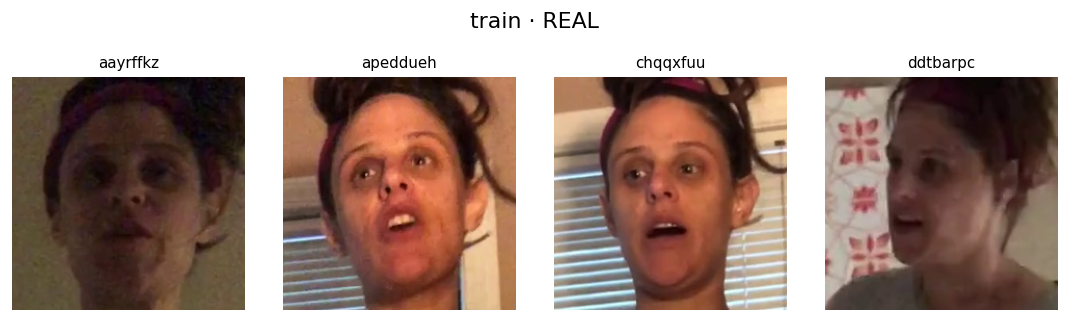

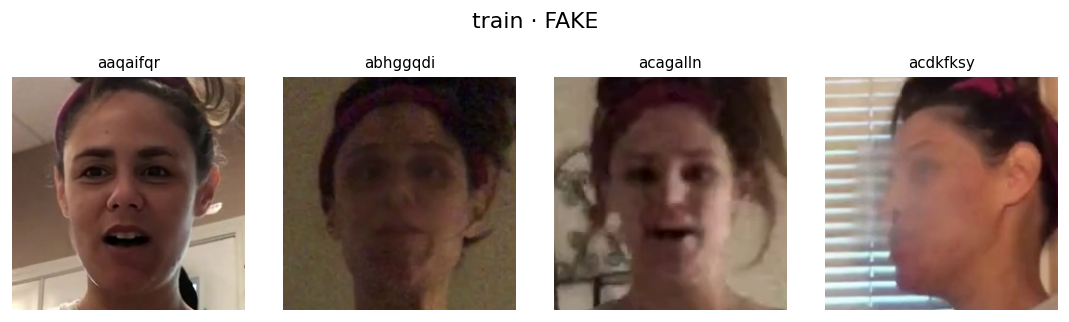

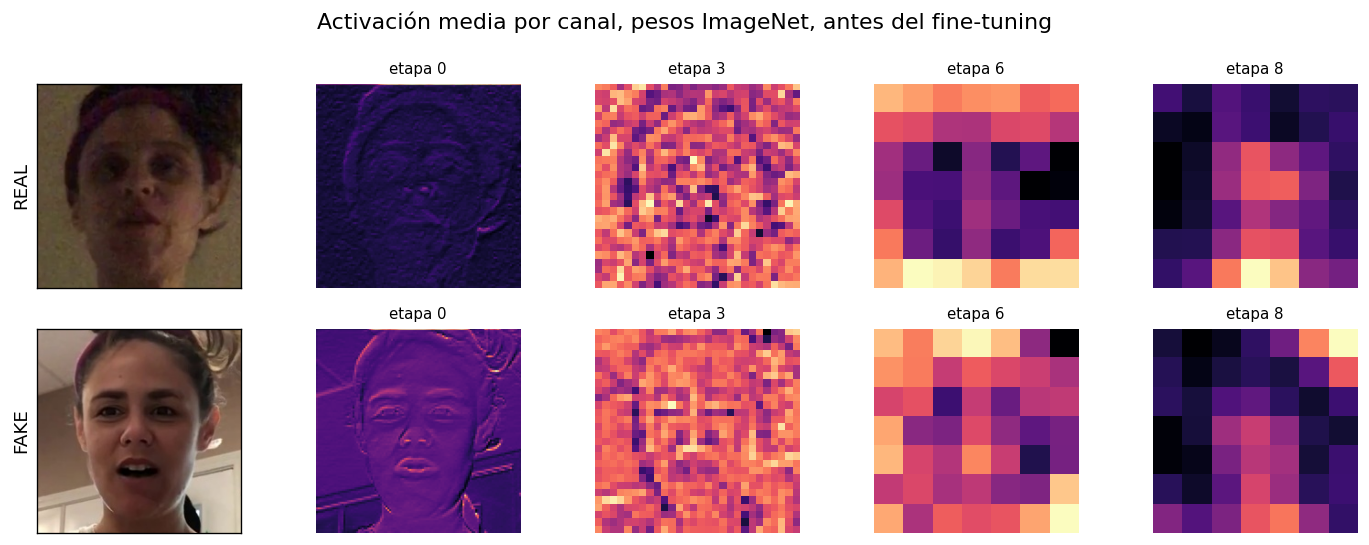

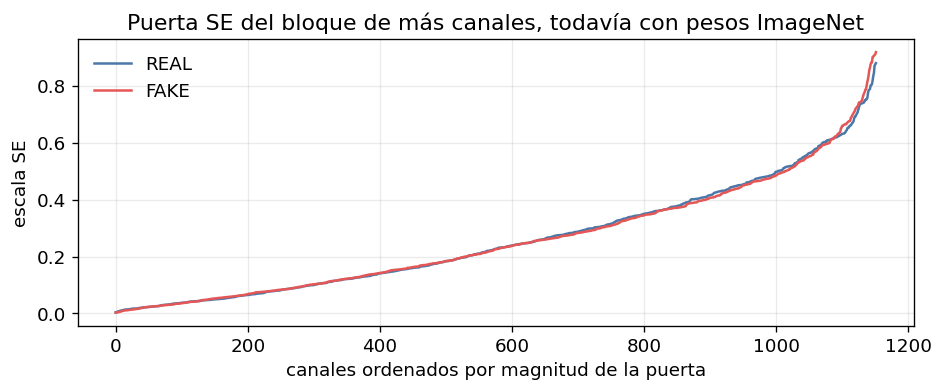

bloques SE observados: 16 | bloque mostrado: features.6.1.block.2


In [ ]:
def show_crops(split_name: str, label_name: str, n: int = 4) -> None:
    rows = [row for row in manifest if row["split"] == split_name and row["label"] == label_name and row["has_face"] == 1]
    # Un frame por vídeo, en orden estable.
    picked = []
    seen = set()
    for row in rows:
        if row["video"] in seen:
            continue
        seen.add(row["video"])
        picked.append(row)
        if len(picked) == n:
            break
    fig, axes = plt.subplots(1, len(picked), figsize=(2.3 * len(picked), 2.6))
    for axis, row in zip(axes, picked):
        axis.imshow(Image.open(row["path"]))
        axis.set_title(row["video"][:8], fontsize=9)
        axis.axis("off")
    fig.suptitle(f"{split_name} · {label_name}", y=1.02)
    fig.tight_layout()
    return fig


fig_real = show_crops("train", "REAL")
fig_real.savefig(FIG_DIR / "03_muestras_real.png", bbox_inches="tight")
plt.show()
fig_fake = show_crops("train", "FAKE")
fig_fake.savefig(FIG_DIR / "03_muestras_fake.png", bbox_inches="tight")
plt.show()


def tensor_from_row(row: dict) -> torch.Tensor:
    image = Image.open(row["path"]).convert("RGB")
    array = TF.to_tensor(image)
    return TF.normalize(array, IMAGENET_MEAN, IMAGENET_STD)


def first_row(split_name: str, label_name: str) -> dict:
    for row in manifest:
        if row["split"] == split_name and row["label"] == label_name and row["has_face"] == 1:
            return row
    raise RuntimeError(f"sin recorte de cara en {split_name} {label_name}")


example_rows = {"REAL": first_row("train", "REAL"), "FAKE": first_row("train", "FAKE")}


def forward_maps(net: nn.Module, image: torch.Tensor) -> tuple[dict, dict]:
    activations = {}
    gates = {}
    handles = []
    for index, stage in enumerate(net.features):
        handles.append(stage.register_forward_hook(lambda _m, _i, out, index=index: activations.__setitem__(index, out.detach().cpu())))
    for name, module in net.named_modules():
        if isinstance(module, SqueezeExcitation):
            handles.append(
                module.register_forward_hook(
                    lambda mod, inputs, _out, name=name: gates.__setitem__(
                        name, mod._scale(inputs[0]).detach().float().cpu().flatten()
                    )
                )
            )
    net.eval()
    with torch.no_grad():
        net(image.unsqueeze(0).to(DEVICE))
    for handle in handles:
        handle.remove()
    return activations, gates


model_se.to(DEVICE).eval()
maps = {}
gates = {}
for label_name, row in example_rows.items():
    maps[label_name], gates[label_name] = forward_maps(model_se, tensor_from_row(row))

stage_ids = [0, 3, 6, 8]
fig, axes = plt.subplots(2, 1 + len(stage_ids), figsize=(12, 4.6))
for row_i, label_name in enumerate(("REAL", "FAKE")):
    axes[row_i, 0].imshow(Image.open(example_rows[label_name]["path"]))
    axes[row_i, 0].set_ylabel(label_name)
    axes[row_i, 0].set_xticks([])
    axes[row_i, 0].set_yticks([])
    for col, stage_id in enumerate(stage_ids, start=1):
        heat = maps[label_name][stage_id][0].mean(0).numpy()
        axes[row_i, col].imshow(heat, cmap="magma")
        axes[row_i, col].set_title(f"etapa {stage_id}", fontsize=9)
        axes[row_i, col].axis("off")
fig.suptitle("Activación media por canal, pesos ImageNet, antes del fine-tuning")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_mapas_intermedios.png", bbox_inches="tight")
plt.show()

gate_names = sorted(gates["REAL"])
late_name = max(gate_names, key=lambda name: gates["REAL"][name].numel())
fig, ax = plt.subplots(figsize=(8, 3.4))
for label_name, color in (("REAL", "#4C78A8"), ("FAKE", "#E45756")):
    values = torch.sort(gates[label_name][late_name]).values.numpy()
    ax.plot(values, label=label_name, color=color)
ax.set_xlabel("canales ordenados por magnitud de la puerta")
ax.set_ylabel("escala SE")
ax.set_title("Puerta SE del bloque de más canales, todavía con pesos ImageNet")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_puerta_se_imagenet.png", bbox_inches="tight")
plt.show()

std_before = {
    label_name: {name: float(gates[label_name][name].std()) for name in gate_names}
    for label_name in ("REAL", "FAKE")
}
(OUT_DIR / "se_std_antes.json").write_text(json.dumps(std_before), encoding="utf-8")
print("bloques SE observados:", len(gate_names), "| bloque mostrado:", late_name)


## 8. Fine-tuning completo, cinco épocas

Las dos redes se entrenan por separado, con el mismo orden de batches (el generador del DataLoader se reinicia con la semilla 42). Entrenamiento con `drop_last` para no dejar un batch de tamaño 1 bajo BatchNorm. Validación en modo eval, donde BatchNorm usa las medias móviles. Se guarda el estado de la época 5, que es el que entra en la hipótesis. La mejor época de validación se anota y no selecciona el modelo.


In [ ]:
class FaceFrames(Dataset):
    def __init__(self, rows: list[dict], train: bool):
        self.rows = rows
        self.train = train

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, index: int):
        row = self.rows[index]
        image = Image.open(row["path"]).convert("RGB")
        if self.train and random.random() < 0.5:
            image = TF.hflip(image)
        tensor = TF.to_tensor(image)
        tensor = TF.normalize(tensor, IMAGENET_MEAN, IMAGENET_STD)
        return tensor, torch.tensor(int(row["y"]), dtype=torch.long), row["video"]


def make_loader(rows: list[dict], train: bool) -> DataLoader:
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        FaceFrames(rows, train=train),
        batch_size=BATCH_SIZE,
        shuffle=train,
        drop_last=train,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
        generator=generator if train else None,
    )


def aggregate(videos: list[str], probs: np.ndarray, targets: np.ndarray) -> tuple[np.ndarray, np.ndarray, list[str]]:
    bucket = defaultdict(list)
    target_of = {}
    for video, prob, target in zip(videos, probs, targets):
        bucket[video].append(float(prob))
        target_of[video] = int(target)
    order = sorted(bucket)
    scores = np.array([float(np.mean(bucket[video])) for video in order])
    y = np.array([target_of[video] for video in order])
    return scores, y, order


def classification_weights(rows: list[dict]) -> torch.Tensor:
    y = np.array([int(row["y"]) for row in rows])
    total = len(y)
    weights = []
    for cls in (0, 1):
        count = max(int((y == cls).sum()), 1)
        weights.append(total / (2 * count))
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


train_rows = [row for row in manifest if row["split"] == "train"]
val_rows = [row for row in manifest if row["split"] == "val"]
print("frames train", len(train_rows), "val", len(val_rows))
print("pesos de clase [REAL, FAKE]", classification_weights(train_rows).tolist())


def fit(net: nn.Module, name: str) -> dict:
    set_seed(SEED)
    net.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=classification_weights(train_rows))
    optimizer = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_loader(train_rows, train=True)
    val_loader = make_loader(val_rows, train=False)
    history = []
    print(f"\n=== {name} | H1 todavía no se lee: primero corre el protocolo ===")
    for epoch in range(1, EPOCHS + 1):
        net.train()
        running = 0.0
        seen = 0
        for batch_x, batch_y, _video in train_loader:
            batch_x = batch_x.to(DEVICE, non_blocking=True)
            batch_y = batch_y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(net(batch_x), batch_y)
            if not torch.isfinite(loss):
                print(f"pérdida no finita en época {epoch}; se detiene {name}")
                break
            loss.backward()
            optimizer.step()
            running += loss.item() * batch_x.size(0)
            seen += batch_x.size(0)
        scheduler.step()

        net.eval()
        probs, targets, videos = [], [], []
        with torch.no_grad():
            for batch_x, batch_y, batch_video in val_loader:
                batch_x = batch_x.to(DEVICE, non_blocking=True)
                logit = net(batch_x)
                prob = torch.softmax(logit, dim=1)[:, 1]
                probs.append(prob.cpu().numpy())
                targets.append(batch_y.numpy())
                videos.extend(list(batch_video))
        scores, y_video, order = aggregate(videos, np.concatenate(probs), np.concatenate(targets))
        auc = float(roc_auc_score(y_video, scores))
        record = {
            "epoch": epoch,
            "train_loss": running / max(seen, 1),
            "val_auc": auc,
            "val_logloss": float(log_loss(y_video, np.clip(scores, 1e-6, 1 - 1e-6), labels=[0, 1])),
            "val_balanced_acc": float(balanced_accuracy_score(y_video, (scores >= 0.5).astype(int))),
            "lr": optimizer.param_groups[0]["lr"],
        }
        history.append(record)
        print(
            f"época {epoch} | loss {record['train_loss']:.4f} | AUC vídeo {record['val_auc']:.4f} "
            f"| logloss {record['val_logloss']:.4f} | bal. acc@0.5 {record['val_balanced_acc']:.4f}"
        )
        if epoch == EPOCHS:
            final_scores = {"videos": order, "y": y_video.tolist(), "score": scores.tolist()}
    torch.save(net.state_dict(), OUT_DIR / f"{name}_epoca5.pt")
    return {"name": name, "history": history, "final": final_scores}


print("ANTES DE MEDIR")
print("H1: el intervalo 5–95 de Δ = AUC(sin SE) - AUC(con SE) queda por debajo de 0.")
print("H2: la pérdida de entrenamiento baja y el AUC de validación no la acompaña (margen 0.05).")
result_se = fit(model_se, "con_se")
result_nose = fit(model_nose, "sin_se")
(OUT_DIR / "historias.json").write_text(
    json.dumps({"con_se": result_se["history"], "sin_se": result_nose["history"]}, indent=2),
    encoding="utf-8",
)


frames train 8216 val 2456
pesos de clase [REAL, FAKE] [7.551470756530762, 0.5354536175727844]
ANTES DE MEDIR
H1: el intervalo 5–95 de Δ = AUC(sin SE) - AUC(con SE) queda por debajo de 0.
H2: la pérdida de entrenamiento baja y el AUC de validación no la acompaña (margen 0.05).

=== con_se | H1 todavía no se lee: primero corre el protocolo ===


época 1 | loss 0.4211 | AUC vídeo 0.9931 | logloss 0.1686 | bal. acc@0.5 0.9080


época 2 | loss 0.1940 | AUC vídeo 0.9960 | logloss 0.1442 | bal. acc@0.5 0.9080


época 3 | loss 0.1246 | AUC vídeo 0.9963 | logloss 0.1183 | bal. acc@0.5 0.9080


época 4 | loss 0.0915 | AUC vídeo 0.9963 | logloss 0.0903 | bal. acc@0.5 0.9097


...

época 2 | loss 0.2881 | AUC vídeo 0.9915 | logloss 0.2427 | bal. acc@0.5 0.8994


época 3 | loss 0.1994 | AUC vídeo 0.9956 | logloss 0.1557 | bal. acc@0.5 0.9063


época 4 | loss 0.1520 | AUC vídeo 0.9962 | logloss 0.1392 | bal. acc@0.5 0.9358


época 5 | loss 0.1162 | AUC vídeo 0.9960 | logloss 0.1372 | bal. acc@0.5 0.9341


2305

época 5 | AUC con SE 0.9958 | AUC sin SE 0.9960 | Δ 0.0002
bootstrap Δ percentiles 5, 50, 95: -0.0016, 0.0000, 0.0022
lectura H1: no concluyente: el intervalo del bootstrap contiene 0. Esta preliminar no separa las dos variantes.
H2: pérdida época 1 → 5: 0.4211 → 0.0627; AUC val 0.9931 → 0.9958. La curva es compatible con H2.
fracción FAKE en val (accuracy del constante FAKE): 0.941
accuracy@0.5 con SE 0.974 | sin SE 0.974
Esas accuracy no deciden la hipótesis.


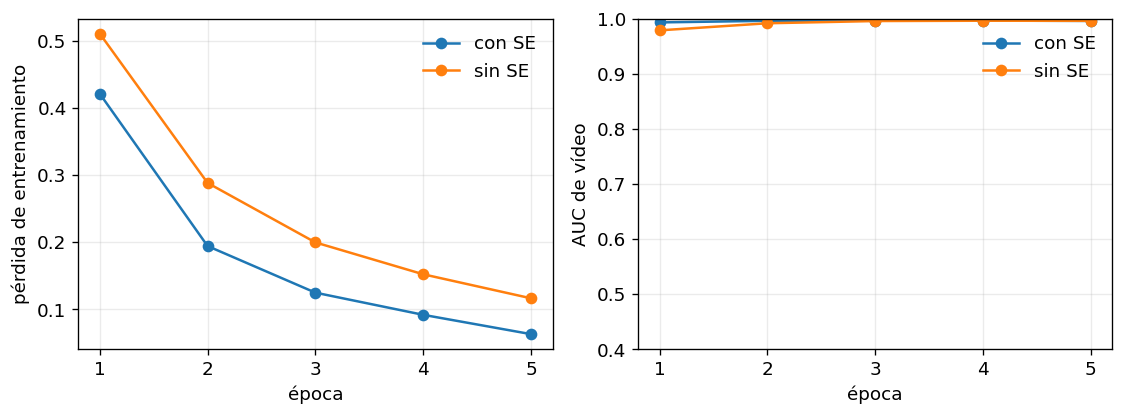

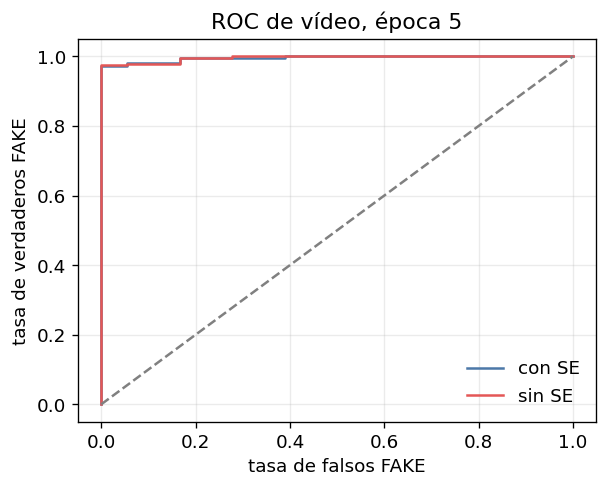

{
  "auc_con_se": 0.995770857362553,
  "auc_sin_se": 0.9959630911188004,
  "delta": 0.00019223375624743966,
  "bootstrap": {
    "n_ok": 1000,
    "delta_p05": -0.0015712744528791622,
    "delta_p50": 1.1102230246251565e-16,
    "delta_p95": 0.0021930359174387013,
    "auc_se_p05_p95": [
      0.9904463431008553,
      0.9992707123499808
    ],
    "auc_nose_p05_p95": [
      0.9909799783359388,
      0.9994110718492344
    ]
  },
  "lectura_h1": "no concluyente: el intervalo del bootstrap contiene 0. Esta preliminar no separa las dos variantes.",
  "h2_compatible": true,
  "accuracy_constante_fake": 0.9413680781758957,
  "accuracy_con_se": 0.9739413680781759,
  "accuracy_sin_se": 0.9739413680781759,
  "n_videos_val": 307,
  "fraccion_caras": 1.0
}


In [ ]:
def paired_bootstrap(y: np.ndarray, score_se: np.ndarray, score_nose: np.ndarray) -> dict:
    rng = np.random.default_rng(SEED)
    deltas = []
    auc_se, auc_nose = [], []
    n = len(y)
    for _ in range(BOOTSTRAP_DRAWS):
        index = rng.integers(0, n, n)
        if len(np.unique(y[index])) < 2:
            continue
        a_se = roc_auc_score(y[index], score_se[index])
        a_nose = roc_auc_score(y[index], score_nose[index])
        auc_se.append(a_se)
        auc_nose.append(a_nose)
        deltas.append(a_nose - a_se)
    deltas = np.asarray(deltas)
    low, mid, high = np.quantile(deltas, [0.05, 0.5, 0.95])
    return {
        "n_ok": int(deltas.size),
        "delta_p05": float(low),
        "delta_p50": float(mid),
        "delta_p95": float(high),
        "auc_se_p05_p95": [float(np.quantile(auc_se, 0.05)), float(np.quantile(auc_se, 0.95))],
        "auc_nose_p05_p95": [float(np.quantile(auc_nose, 0.05)), float(np.quantile(auc_nose, 0.95))],
    }


y = np.asarray(result_se["final"]["y"])
score_se = np.asarray(result_se["final"]["score"])
# Misma lista de vídeos: ambos fit recorren el val loader sin shuffle.
assert result_se["final"]["videos"] == result_nose["final"]["videos"]
score_nose = np.asarray(result_nose["final"]["score"])
auc_se = float(roc_auc_score(y, score_se))
auc_nose = float(roc_auc_score(y, score_nose))
delta = auc_nose - auc_se
boot = paired_bootstrap(y, score_se, score_nose)

acc_se = float(((score_se >= 0.5).astype(int) == y).mean())
acc_nose = float(((score_nose >= 0.5).astype(int) == y).mean())
acc_constant = float((np.ones_like(y) == y).mean())

hist_se = result_se["history"]
loss_drop = hist_se[0]["train_loss"] - hist_se[-1]["train_loss"]
auc_gain = hist_se[-1]["val_auc"] - hist_se[0]["val_auc"]
h2_match = loss_drop > 0 and auc_gain < 0.05

if boot["delta_p95"] < 0:
    reading = "compatible con H1 en esta partición: el intervalo queda por debajo de 0."
elif boot["delta_p05"] > 0:
    reading = "en contra de H1 en esta partición: sin SE el AUC sube y el intervalo queda por encima de 0."
else:
    reading = "no concluyente: el intervalo del bootstrap contiene 0. Esta preliminar no separa las dos variantes."

print(f"época 5 | AUC con SE {auc_se:.4f} | AUC sin SE {auc_nose:.4f} | Δ {delta:.4f}")
print(f"bootstrap Δ percentiles 5, 50, 95: {boot['delta_p05']:.4f}, {boot['delta_p50']:.4f}, {boot['delta_p95']:.4f}")
print("lectura H1:", reading)
print(
    f"H2: pérdida época 1 → 5: {hist_se[0]['train_loss']:.4f} → {hist_se[-1]['train_loss']:.4f}; "
    f"AUC val {hist_se[0]['val_auc']:.4f} → {hist_se[-1]['val_auc']:.4f}. "
    + ("La curva es compatible con H2." if h2_match else "La curva no cumple el criterio previo de H2.")
)
print(f"fracción FAKE en val (accuracy del constante FAKE): {acc_constant:.3f}")
print(f"accuracy@0.5 con SE {acc_se:.3f} | sin SE {acc_nose:.3f}")
print("Esas accuracy no deciden la hipótesis.")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
epochs = [row["epoch"] for row in hist_se]
axes[0].plot(epochs, [row["train_loss"] for row in hist_se], marker="o", label="con SE")
axes[0].plot(epochs, [row["train_loss"] for row in result_nose["history"]], marker="o", label="sin SE")
axes[0].set_xlabel("época")
axes[0].set_ylabel("pérdida de entrenamiento")
axes[0].legend(frameon=False)
axes[1].plot(epochs, [row["val_auc"] for row in hist_se], marker="o", label="con SE")
axes[1].plot(epochs, [row["val_auc"] for row in result_nose["history"]], marker="o", label="sin SE")
axes[1].set_xlabel("época")
axes[1].set_ylabel("AUC de vídeo")
axes[1].set_ylim(0.4, 1.0)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_curvas.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for scores, label_name, color in (
    (score_se, "con SE", "#4C78A8"),
    (score_nose, "sin SE", "#E45756"),
):
    fpr, tpr, _ = roc_curve(y, scores)
    ax.plot(fpr, tpr, color=color, label=label_name)
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set_xlabel("tasa de falsos FAKE")
ax.set_ylabel("tasa de verdaderos FAKE")
ax.set_title("ROC de vídeo, época 5")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_roc.png", bbox_inches="tight")
plt.show()

summary = {
    "auc_con_se": auc_se,
    "auc_sin_se": auc_nose,
    "delta": delta,
    "bootstrap": boot,
    "lectura_h1": reading,
    "h2_compatible": h2_match,
    "accuracy_constante_fake": acc_constant,
    "accuracy_con_se": acc_se,
    "accuracy_sin_se": acc_nose,
    "n_videos_val": int(len(y)),
    "fraccion_caras": float(np.mean([row["has_face"] for row in manifest])),
}
(OUT_DIR / "lectura_preliminar.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))


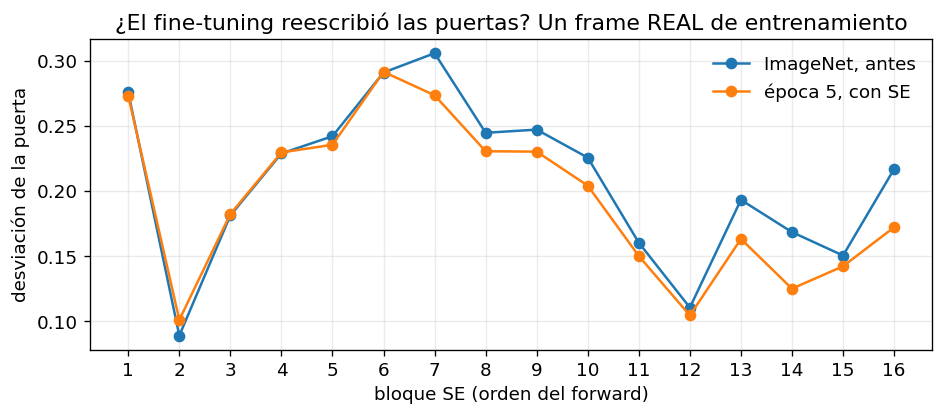

In [ ]:
# La misma pareja de frames de la sección 7, ahora con los pesos de la época 5.
std_before = json.loads((OUT_DIR / "se_std_antes.json").read_text(encoding="utf-8"))
model_se.load_state_dict(torch.load(OUT_DIR / "con_se_epoca5.pt", map_location=DEVICE, weights_only=True))
_maps, gates_after = forward_maps(model_se, tensor_from_row(example_rows["REAL"]))
names_se = sorted(std_before["REAL"])
before = [std_before["REAL"][name] for name in names_se]
after = [float(gates_after[name].std()) for name in names_se]
fig, ax = plt.subplots(figsize=(8, 3.6))
xpos = np.arange(len(names_se))
ax.plot(xpos, before, marker="o", label="ImageNet, antes")
ax.plot(xpos, after, marker="o", label="época 5, con SE")
ax.set_xticks(xpos)
ax.set_xticklabels([str(i + 1) for i in xpos])
ax.set_xlabel("bloque SE (orden del forward)")
ax.set_ylabel("desviación de la puerta")
ax.set_title("¿El fine-tuning reescribió las puertas? Un frame REAL de entrenamiento")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_puertas_antes_despues.png", bbox_inches="tight")
plt.show()


## 9. Qué queda fuera, a propósito

Esta corrida usa una parte de DFDC, una semilla y un solo corte de identidades. El bootstrap no crea una segunda semilla: solo remuestrea los vídeos de esta validación. El metadato no dice qué método generó cada FAKE, así que un Δ distinto de cero seguiría siendo un resultado dentro del mismo saco de manipulaciones, no una prueba de generalización entre métodos.

La Fase C del curso pide justamente ese otro dominio. Las intervenciones que este cuaderno deja nombradas y sin ejecutar, para no mezclarlas con SE, son: SiLU frente a ReLU dentro del MBConv, residual aditivo frente a concatenación, y learning rate más bajo en el tronco que en la cabeza. También queda sin hacer el contraste contra features congeladas del estilo de Ojha et al. (2023), que es el related work con el que hay que medirse si la puerta SE resulta frágil.